# 02 · Simple Demo — Can the sensors tell how worn a tool is?

**The question:** a milling tool gets duller every time it cuts. The dullness is measured as **flank wear VB**
(in mm; a new tool ≈ 0 mm, a worn-out tool ≈ 0.5+ mm). Measuring it means stopping the machine and using a
microscope. **Can a model estimate VB just by "listening" to the machine's sensors during a cut?**

**The plan:** summarize each cutting run into a few numbers → train a model on some tools → test it on tools it
has never seen.

Prerequisite: `python scripts/make_dataset.py` (creates `data/processed/`). Everything below runs in seconds.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

from milling.data import FS, SIGNALS
from milling.utils import INK_MUTED, PALETTE, set_plot_style

set_plot_style()
pd.set_option("display.precision", 3)
FIG = ROOT / "reports/figures"

runs = pd.read_csv(ROOT / "data/processed/runs.csv")
signals = np.load(ROOT / "data/processed/signals.npy")  # (runs, 6 channels, 9000 samples)
print(f"{len(runs)} runs from {runs.case.nunique()} tools, each with {signals.shape[1]} sensor signals")

167 runs from 16 tools, each with 6 sensor signals


## Step 1 · What one run looks like
Each run is 36 s of cutting recorded by 6 sensors: spindle-motor current (AC and DC), vibration (table and
spindle) and acoustic emission — the "sound" of the metal (table and spindle). The tool enters the metal
after a few seconds and leaves near the end. We only use the **steady cutting part** (shaded), where the
signal reflects the tool's condition rather than the tool entering or leaving.

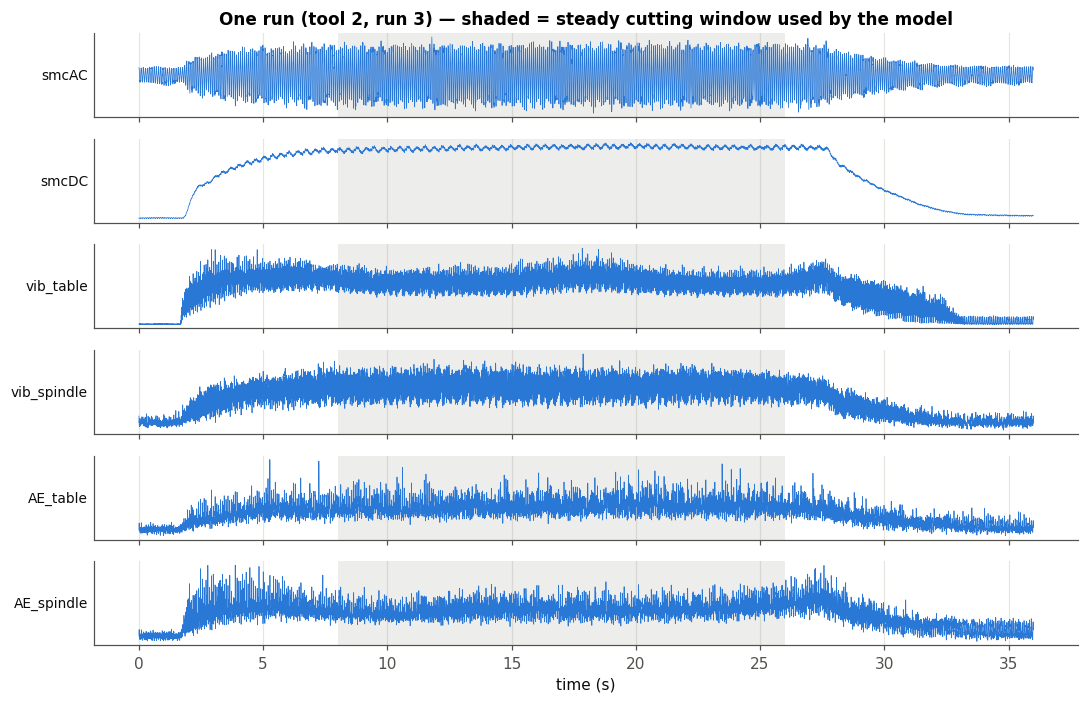

In [2]:
WINDOW = (2000, 6500)  # samples → 8 s to 26 s
i = runs.index[(runs.case == 2) & (runs.run == 3)][0]
t = np.arange(signals.shape[-1]) / FS
fig, axes = plt.subplots(6, 1, figsize=(10, 6.5), sharex=True)
for k, (ax, name) in enumerate(zip(axes, SIGNALS)):
    ax.plot(t, signals[i, k], lw=0.5, color=PALETTE[0])
    ax.axvspan(WINDOW[0] / FS, WINDOW[1] / FS, color="#8a8984", alpha=0.15, lw=0)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
    ax.set_yticks([])
axes[0].set_title("One run (tool 2, run 3) — shaded = steady cutting window used by the model")
axes[-1].set_xlabel("time (s)")
fig.tight_layout()

## Step 2 · Turn each run into 7 numbers
A model can't easily use 6 × 9000 raw samples from only ~145 runs. So we summarize each run by **how strong
each signal is** during steady cutting (its RMS, the average signal strength), plus whether the metal is steel.
We keep only runs where VB was actually measured (145 runs).

In [3]:
steady = signals[:, :, WINDOW[0]:WINDOW[1]]
rms = np.sqrt(np.mean(steady**2, axis=2))

data = runs[["case", "run", "time", "VB", "valid", "material_name"]].copy()
for k, name in enumerate(SIGNALS):
    data[f"{name}_strength"] = rms[:, k]
data["is_steel"] = (runs.material_name == "steel").astype(int)
data = data[data.valid & data.VB.notna()].rename(columns={"case": "tool"}).reset_index(drop=True)

FEATURES = [f"{name}_strength" for name in SIGNALS] + ["is_steel"]
print(f"{len(data)} runs, each described by {len(FEATURES)} numbers:")
data[["tool", "run", "VB"] + FEATURES].head()

145 runs, each described by 7 numbers:


,tool,run,VB,smcAC_strength,smcDC_strength,vib_table_strength,vib_spindle_strength,AE_table_strength,AE_spindle_strength,is_steel
0,1,1,0.00,1.804,6.965,2.051,0.650,0.203,0.215,0
1,1,4,0.11,1.948,7.499,1.813,0.589,0.219,0.235,0
2,1,6,0.20,2.392,9.211,1.136,0.525,0.245,0.243,0
3,1,7,0.24,2.469,9.777,1.911,0.443,0.222,0.337,0
4,1,8,0.29,2.698,9.983,1.060,0.443,0.283,0.300,0


## Step 3 · Hide some tools for testing
Runs from the same tool look very alike. If we tested on runs from a tool the model already trained on, it could
just recognise the tool. So we **hide 4 whole tools** — 2 cast iron, 2 steel, picked at random — and train on
the other 12. (Tool 6 is left out of the draw: it has only one run.)

In [4]:
rng = np.random.default_rng(0)
tool_material = data[data.tool != 6].groupby("tool").material_name.first()
TEST_TOOLS = sorted(
    rng.choice(tool_material[tool_material == "cast_iron"].index, 2, replace=False).tolist()
    + rng.choice(tool_material[tool_material == "steel"].index, 2, replace=False).tolist()
)
is_test = data.tool.isin(TEST_TOOLS)
train, test = data[~is_test], data[is_test]
print(f"test tools : {TEST_TOOLS}  ({len(test)} runs)")
print(f"train tools: {sorted(train.tool.unique())}  ({len(train)} runs)")

test tools : [7, 8, 10, 12]  (34 runs)
train tools: [1, 2, 3, 4, 5, 6, 9, 11, 13, 14, 15, 16]  (111 runs)


## Step 4 · Train a model and score it
* **Model:** a *random forest* — many small decision trees that each vote on the wear; the answer is their average.
* **Bar to beat:** always guessing the average wear of the training runs (a model that learned nothing).
* **Score:** average error in mm — how far off the prediction is, on average. Lower is better.

In [5]:
model = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0)
model.fit(train[FEATURES], train.VB)
test = test.assign(predicted=model.predict(test[FEATURES]), guess=train.VB.mean())

err_model = mean_absolute_error(test.VB, test.predicted)
err_guess = mean_absolute_error(test.VB, test.guess)
print(f"Guess the average : {err_guess:.3f} mm average error")
print(f"Random forest     : {err_model:.3f} mm average error  ({1 - err_model / err_guess:.0%} smaller)")

Guess the average : 0.183 mm average error
Random forest     : 0.108 mm average error  (41% smaller)


## Step 5 · See it: real vs predicted wear on the hidden tools
Each panel is a tool the model **never saw**. Blue = wear measured with the microscope after each run.
Orange = the model's estimate from that run's sensor signals alone (it is *not* told the time).
Dashed = the "guess the average" answer.

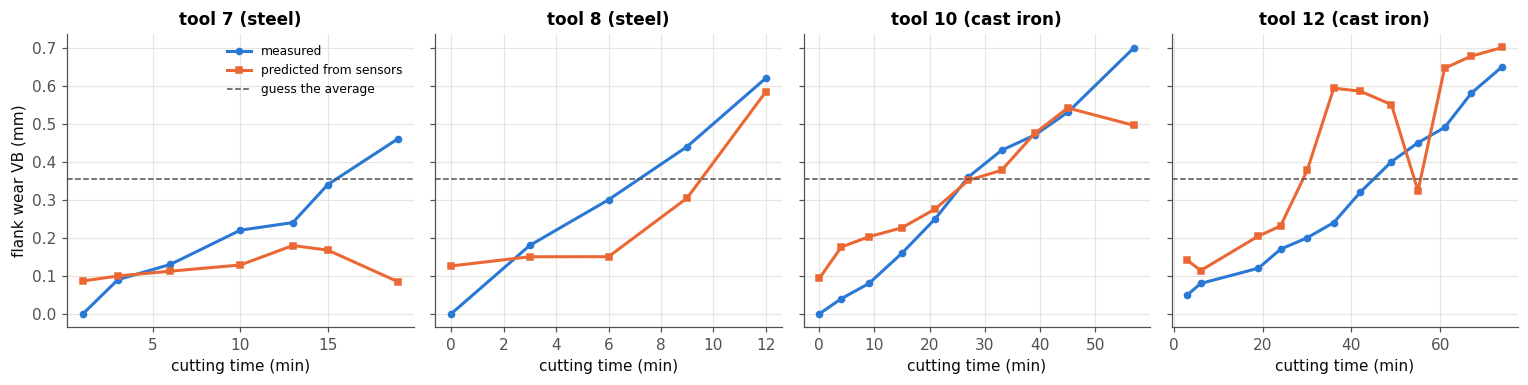

In [6]:
fig, axes = plt.subplots(1, len(TEST_TOOLS), figsize=(14, 3.6), sharey=True)
for ax, tool in zip(axes, TEST_TOOLS):
    g = test[test.tool == tool].sort_values("time")
    ax.plot(g.time, g.VB, "-o", ms=4, color=PALETTE[0], label="measured")
    ax.plot(g.time, g.predicted, "-s", ms=4, color=PALETTE[1], label="predicted from sensors")
    ax.axhline(g.guess.iloc[0], ls="--", lw=1, color=INK_MUTED, label="guess the average")
    ax.set(title=f"tool {tool} ({g.material_name.iloc[0].replace('_', ' ')})", xlabel="cutting time (min)")
axes[0].set_ylabel("flank wear VB (mm)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "demo_wear_curves.png")

**How to read it**
* **Tools 8 and 10:** the prediction follows the real wear closely, purely from how the signals change.
* **Tool 12:** the overall trend is right, but it jumps around at 35–55 min. Each run is predicted on its own,
  so one run with unusual signals gives one odd prediction.
* **Tool 7 (steel):** the prediction stays low while the tool keeps wearing. The model misses it.

So the sensors carry real wear information, but a single run's estimate can be noisy.

## Step 6 · Were we lucky with the 4 hidden tools?
With only 4 test tools, the score depends on which ones were drawn. A fairer test: hide **each of the 16 tools in
turn**, train on the other 15, and average over all of them.

In [7]:
def hide_each_tool(columns):
    """Predict every run with a model that never saw that run's tool."""
    pred = pd.Series(np.nan, index=data.index)
    for tool in data.tool.unique():
        hide = data.tool == tool
        m = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)
        pred[hide] = m.fit(data.loc[~hide, columns], data.loc[~hide, "VB"]).predict(data.loc[hide, columns])
    return pred


all_pred = hide_each_tool(FEATURES)
all_guess = pd.Series({i: data.VB[data.tool != t].mean() for i, t in data.tool.items()})

worn = data.VB > 0.6
print("Every tool hidden in turn:")
print(f"  guess the average : {mean_absolute_error(data.VB, all_guess):.3f} mm average error")
print(f"  random forest     : {mean_absolute_error(data.VB, all_pred):.3f} mm average error")
print("Random forest error, split by how worn the tool really was:")
print(f"  VB up to 0.6 mm   : {mean_absolute_error(data.VB[~worn], all_pred[~worn]):.3f} mm ({(~worn).sum()} runs)")
print(f"  VB above 0.6 mm   : {mean_absolute_error(data.VB[worn], all_pred[worn]):.3f} mm ({worn.sum()} runs)")

Every tool hidden in turn:
  guess the average : 0.200 mm average error
  random forest     : 0.132 mm average error
Random forest error, split by how worn the tool really was:
  VB up to 0.6 mm   : 0.102 mm (126 runs)
  VB above 0.6 mm   : 0.331 mm (19 runs)


The 4-tool split was a bit on the lucky side (0.108 mm there vs 0.132 mm over all tools), but the conclusion
holds across all 16 tools: the sensors cut the error well below guessing. The weak spot is **very worn tools**
(VB above 0.6 mm), where the error is about 3× larger: most tools were stopped near the wear limit, so only 19 of
the 145 runs are that worn, and more than half of those come from just 3 tools. The model has barely seen what a
very worn tool sounds like.

## Step 7 · Which sensors matter?
Take away one input at a time, rerun the all-tools test from Step 6, and see how much worse the error gets.
A big increase means the model really needs that sensor. (Takes ~20 s.)

,extra error (mm)
vib_spindle_strength,0.015
vib_table_strength,0.010
AE_table_strength,0.003
AE_spindle_strength,0.001
smcDC_strength,-0.000
is_steel,-0.000
smcAC_strength,-0.001


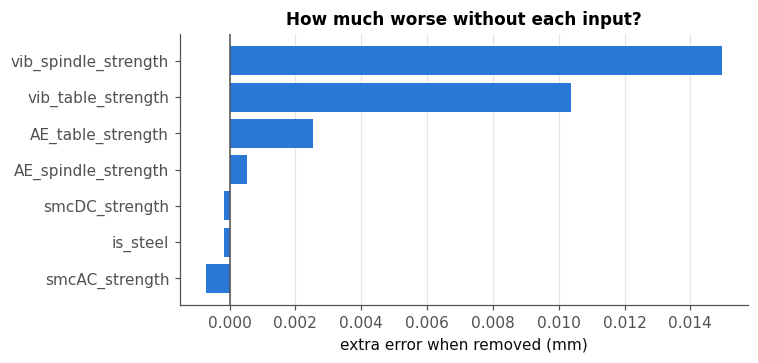

In [8]:
baseline = mean_absolute_error(data.VB, all_pred)
extra_error = pd.Series({
    f: mean_absolute_error(data.VB, hide_each_tool([c for c in FEATURES if c != f])) - baseline for f in FEATURES
}).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(extra_error.index, extra_error.values, color=PALETTE[0])
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="extra error when removed (mm)", title="How much worse without each input?")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "demo_importance.png")
extra_error.sort_values(ascending=False).round(3).to_frame("extra error (mm)")

* **Spindle vibration** is the input the model misses most, followed by table vibration.
* The **two motor-current channels** (AC and DC) cost nothing when removed one at a time. They measure the same
  thing, so when one is gone the other covers for it.
* **is_steel** adds nothing: the signal levels already give away which metal is being cut.
* No single sensor is enough on its own. The model works by **combining** them.

## Takeaways
1. **Sensors do reveal tool wear.** From 7 simple numbers per run, a model estimates wear on tools it has never
   seen, with clearly less error than guessing (0.13 vs 0.20 mm).
2. **It works by combining sensors,** with spindle vibration the one it can least do without.
3. **Main limitation: very worn tools.** The dataset has few of them, so predictions there are least reliable.

*Want more?* `03_detailed_results.ipynb` compares more models and inputs (including a neural network on the raw
signals and a cutting-time baseline) using the full pipeline in `scripts/`.